# Dermoscopy Copilot — 04. Active Learning

## Purpose of this notebook

Annotating dermoscopic images is expensive, because every label has to come from a dermatologist. Active learning tries to reduce this annotation cost by involving the model in the labelling process. Instead of labelling images at random, the model selects the images it considers most informative and queries an oracle, the human annotator, for their labels. In this notebook we test whether this approach allows the classifier to approach the performance of the passive baseline of notebook `03_passive_baseline.ipynb` while using only part of the labelled data.

We use the same linear layer (`D → 7`) and the same frozen `tf_efficientnetv2_s.in21k_ft_in1k` features as notebook `02_feature_extraction.ipynb`. The main methodological choices are the following:

- **Pool-based active learning in batches:** All the unlabelled images are available from the start. The model begins with 10% of the training images labelled and, in each cycle, queries 300 images, is retrained and is evaluated, until 50% of the training images are labelled.
- **Query strategies:** Three uncertainty sampling strategies (least confidence, margin and entropy), a hybrid strategy that combines uncertainty and diversity sampling, and random sampling, which represents labelling without active learning.
- **Simulated oracle:** The oracle returns the diagnoses stored in the dataset. To study annotation quality, we also use a noisy oracle that labels 10% of the queried images wrongly.
- **Evaluation:** The macro F1-score on the validation set is recorded after every cycle, each strategy is repeated with 10 seeds, and the strategies are compared with paired statistical tests. The test set is used only once, at the end.
- **Annotation cost:** We report how many labelled images each strategy needs to reach 90% and 95% of the performance obtained with all the labels.

The experiments were run with the scripts in the root of the repository, and their results are saved in `results/`. This notebook loads those results.

This notebook requires the `features/features_<BACKBONE>/` folder produced by notebook `02_feature_extraction.ipynb`, the baseline results in `results/results_baseline/results_<BACKBONE>/` produced by notebook `03_passive_baseline.ipynb`, and the active learning results in `results/tables/` and `results/figures/`.

## 1. Library imports

In [37]:
import copy                         # to save a copy of the model weights (early stopping)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch                        # tensors and model training
import torch.nn as nn               # linear layer and loss function
from IPython.display import Image as IPImage, display   # shows the saved figures
from scipy.stats import wilcoxon    # paired, non-parametric statistical test
from sklearn.cluster import KMeans  # k-means clustering, used by the hybrid query strategy
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score
from sklearn.model_selection import train_test_split   # stratified sampling of the initial labelled set

## 2. Configuration

`BACKBONE` must match notebooks 02 and 03, so that the same features are used. The active learning protocol is defined by `INIT_FRAC` (10% of the training images are labelled at the start), `BATCH` (300 images are queried in each cycle) and `MAX_FRAC` (the process stops when 50% of the training images are labelled). Each query strategy is repeated with the 10 `SEEDS`, and `NOISE` is the fraction of queried images that the noisy oracle labels wrongly.

The results shown in this notebook were produced by the following scripts, which can be run again, in this order, to reproduce them from scratch:

1. `active_learning.py` runs the five query strategies with the 10 seeds.
2. `al_results.py` draws the learning curves and counts the classes queried by each strategy.
3. `al_stats.py` performs the statistical tests.
4. `al_labels_to_target.py` computes the annotation cost of each strategy.
5. `al_final.py` evaluates the best strategy on the test set and runs the noisy oracle experiment.

In [38]:
BACKBONE = "tf_efficientnetv2_s.in21k_ft_in1k" 

# Base path, one level up if the notebook is inside the 'notebooks' folder
BASE_DIR = Path("..") if Path.cwd().name == "notebooks" else Path(".")
FEATS = BASE_DIR / "features" / f"features_{BACKBONE}"   # directory
BASELINE = BASE_DIR / "results" / "results_baseline" / f"results_{BACKBONE}" / "baseline_metrics.json"
TABLES = BASE_DIR / "results" / "tables"
FIGURES = BASE_DIR / "results" / "figures"

INIT_FRAC = 0.10          # 10% of the training images are labelled at the start
BATCH = 300               # number of images requested in each cycle
MAX_FRAC = 0.50           # stop when 50% of the training images are labelled
SEEDS = list(range(10))   # same 10 seeds as in active_learning.py
NOISE = 0.10              # fraction of queried images that the noisy oracle labels wrongly

CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]   # class names (in the order of the labels 0 to 6)

# Saved results of the active learning experiments
saved = ["al_curves.csv", "al_requested_classes.csv", "al_stats.csv", "al_labels_to_target.csv", "al_final_runs.csv", "al_test_results.csv"]
for f in saved:
    print(f"{f:28s}", "found" if (TABLES / f).exists() else "MISSING")

al_curves.csv                found
al_requested_classes.csv     found
al_stats.csv                 found
al_labels_to_target.csv      found
al_final_runs.csv            found
al_test_results.csv          found


## 3. Data loading

The features of each split are loaded from the folder produced by notebook 02. In the training set each image appears three times (the original and two augmented copies), while in the validation and test sets each image has 8 views. Only the original training images form the unlabelled pool, and when an image is labelled its three versions are used for training. The following functions are used:

- `load_split` loads the features, labels, image identifiers and augmentation indices of a split.
- `initial_split` selects the initial labelled set, 10% of the training images, stratified by class so that every class is represented from the start.
- `load_data` loads the three splits and records which original image each training row belongs to, so that the three versions of an image always receive the same label.

In [39]:
def load_split(split):
    # Loads the features, labels, image ids and augmentation indices of a split
    d = np.load(f"{FEATS}/{split}_features.npz", allow_pickle=True)
    return d["X"].astype("float32"), d["y"], d["image_ids"], d["aug_idx"]


def initial_split(y_orig, seed):
    # Selects 10% of the training images, stratified by class (True = labelled)
    idx = np.arange(len(y_orig))
    labelled, _ = train_test_split(idx, train_size=INIT_FRAC, stratify=y_orig, random_state=seed)
    mask = np.zeros(len(y_orig), dtype=bool)
    mask[labelled] = True
    return mask


def load_data():
    # Loads the three splits and links each row of the training features to its original image.
    # Each training image appears three times (original and two augmented copies).
    # All three versions must receive the same label when the image is labelled.
    Xtr, ytr, idtr, augtr = load_split("train")
    Xva, yva, _, _ = load_split("val")
    Xte, yte, _, _ = load_split("test")
    orig = np.where(augtr == 0)[0]  # rows of the original images
    ids_orig = idtr[orig]
    # Link each row of the training features to its original image
    row_to_img = pd.Series(np.arange(len(ids_orig)), index=ids_orig).reindex(idtr).values
    # Return all the data in a dictionary
    return dict(Xtr=Xtr, ytr=ytr, idtr=idtr, orig=orig, ids_orig=ids_orig, y_orig=ytr[orig], row_to_img=row_to_img, Xva=Xva, yva=yva, Xte=Xte, yte=yte)

In [40]:
d = load_data()
print("Training features:", d["Xtr"].shape, "| original images (unlabelled pool):", len(d["y_orig"]))
print("Validation features:", d["Xva"].shape, "| test features:", d["Xte"].shape)

# Number of images of each class in the pool, validation and test sets
pd.DataFrame({"pool": np.bincount(d["y_orig"], minlength=7), "validation": np.bincount(d["yva"], minlength=7), "test": np.bincount(d["yte"], minlength=7)}, index=CLASSES).T

Training features: (21459, 1280) | original images (unlabelled pool): 7153
Validation features: (1431, 8, 1280) | test features: (1431, 8, 1280)


,akiec,bcc,bkl,df,mel,nv,vasc
pool,234,366,785,82,795,4789,102
validation,47,74,157,16,159,958,20
test,46,74,157,17,159,958,20


## 4. Model

The classifier is the same as in notebook `03_passive_baseline.ipynb`, a single linear layer (`D → 7`) trained on top of the frozen features. Only this layer is trained, so retraining the model after each query takes only a few seconds. The model works as follows:

- **Training:** The loss gives more importance to the rare classes, using class weights inversely proportional to class frequency.
- **Initial training:** With the initial 10% labelled set, the model is trained with early stopping on the validation macro F1-score, as in the baseline.
- **Retraining:** After each query, the model is retrained for 3 epochs with the new labelled set.
- **Prediction:** For validation and test images, the class probabilities are the average of the 8 views.

In [41]:
class LinearHead:
    # The model receives the 1280 features of each image and gives one score for each of the 7 classes.
    # The EfficientNetV2-S is frozen, so only this final layer is trained.
    def __init__(self, seed=0, n_features=1280, n_classes=7):
        # Creates the layer and the optimiser, with the same values as the baseline, so that the comparison between both is fair.
        torch.manual_seed(seed) # running again gives the same initial weights
        self.net = nn.Linear(n_features, n_classes)
        self.opt = torch.optim.Adam(self.net.parameters(), lr=1e-3, weight_decay=1e-4)

    def fit(self, X, y, epochs=3, X_val=None, y_val=None, patience=10):
        # Trains the model, giving more importance to the rare classes.
        # In the initial training, stops when the validation F1 no longer improves (early stopping).
        n = np.bincount(y, minlength=7).clip(min=1)  # class weights inversely proportional to class frequency
        w = torch.tensor(len(y) / (7 * n), dtype=torch.float32)
        loss_fn = nn.CrossEntropyLoss(weight=w)
        X_t, y_t = torch.tensor(X), torch.tensor(y, dtype=torch.long)
        best, state, wait = -1, None, 0
        for _ in range(epochs):
            perm = torch.randperm(len(X_t))
            for i in range(0, len(perm), 256): # train on mini-batches of 256 images at a time
                b = perm[i:i + 256]
                self.opt.zero_grad()
                loss_fn(self.net(X_t[b]), y_t[b]).backward()
                self.opt.step()
            if X_val is not None: # only with the initial 10%
                f1 = f1_score(y_val, self.predict_proba(X_val).argmax(1), average="macro")
                if f1 > best:
                    best, state, wait = f1, copy.deepcopy(self.net.state_dict()), 0
                else:
                    wait += 1
                    if wait >= patience:
                        break
        if state is not None:  # restore the version with the best weights
            self.net.load_state_dict(state)
        return self

    def predict_proba(self, X):
        # Returns the class probabilities.
        # For validation and test images, they are the average of the 8 views.
        with torch.no_grad():
            X = torch.tensor(X)
            if X.ndim == 3:  # 3 dimensions (images, views and features)
                N, V, D = X.shape
                p = torch.softmax(self.net(X.reshape(N * V, D)), 1).reshape(N, V, -1)
                return p.mean(1).numpy()   # average of the 8 views
            return torch.softmax(self.net(X), 1).numpy()

## 5. Query strategies

A query strategy decides which images of the unlabelled pool are sent to the oracle. We use two types of query strategies:

- **Uncertainty sampling:** the model queries the images it is most uncertain about, because their labels are expected to be the most informative.
- **Diversity sampling:** the model queries images that are different from each other.

Each strategy gives a score to every image in the pool and returns the images ordered from the most to the least informative. The five strategies compared are the following:

- **Least confidence (uncertainty):** queries the images where the probability of the predicted class is lowest.
- **Margin (uncertainty):** queries the images where the two most likely classes have very close probabilities.
- **Entropy (uncertainty):** queries the images whose probability is spread over many classes.
- **Hybrid (uncertainty and diversity):** keeps the 10% most uncertain images by entropy, groups them into 300 clusters of similar images with k-means and queries the image closest to the centre of each cluster. In this way the queried images are both uncertain and different from each other.
- **Random sampling:** queries images at random, without using the model. It represents labelling without active learning and is used for comparison.

In [42]:
# Query strategies
# Each strategy returns the pool images ordered from the most to the least informative, together with their scores
def least_confidence(model, X):
    # Chooses the images where the model is least sure about its predicted class
    p = model.predict_proba(X)
    scores = 1 - p.max(axis=1)  # a low top probability means high uncertainty
    return np.argsort(-scores), scores  # highest scores first

def margin_sampling(model, X):
    # Chooses the images where the two most likely classes have very close probabilities.
    p = np.sort(model.predict_proba(X), axis=1)
    scores = 1 - (p[:, -1] - p[:, -2])  # a small gap between the top two means high uncertainty
    return np.argsort(-scores), scores

def entropy_sampling(model, X):
    # Chooses the images whose probability is spread over many classes (highest entropy)
    p = model.predict_proba(X)
    scores = -(p * np.log(p + 1e-12)).sum(axis=1) # the tiny constant avoids taking the log of zero (error)
    return np.argsort(-scores), scores

def random_sampling(model, X):
    # Chooses the images at random, without using the model.
    # This is the baseline that represents labelling without active learning, used for comparison.
    return np.random.permutation(len(X)), None

def hybrid_sampling(model, X, n=BATCH, frac=0.10):
    # Chooses images that are both uncertain and different from each other.
    # The 10% most uncertain images (by entropy) are grouped into n clusters with k-means, and the image closest to the centre of each cluster is selected.
    order, _ = entropy_sampling(model, X)
    k = max(n, int(frac * len(X)))
    cand = order[:k]  # the most uncertain images are the candidates
    km = KMeans(n_clusters=n, n_init=1, random_state=0).fit(X[cand])
    dist = km.transform(X[cand])  # distance of each candidate to each cluster centre
    chosen = list(dict.fromkeys(cand[dist.argmin(axis=0)]))  # closest image to each centre
    if len(chosen) < n:  # if two centres picked the same image, fill the rest with the next most uncertain images
        used = set(chosen)
        rest = [i for i in cand if i not in used]
        chosen += rest[:n - len(chosen)]
    return np.array(chosen), None

## 6. Active learner

The `ActiveLearner` class combines the model with a query strategy and performs the three steps of each active learning cycle:

- `query` selects the most informative images of the unlabelled pool, which are sent to the oracle.
- `teach` retrains the model with the labelled set, now including the newly labelled images.
- `score` evaluates the model with the macro F1-score.

The dictionary `STRATEGIES` links the name of each strategy to the function that selects the images. In this way, all strategies are run with exactly the same code, and the only difference between them is how the images are queried, which makes the comparison fair.

In [43]:
# Active learner
# Combines the model with a query strategy.
# In each cycle it chooses the images to label (query), learns from their labels (teach) and is evaluated (score).
class ActiveLearner:
    def __init__(self, estimator, query_strategy):
        # Keeps the model and the query strategy that will be used in every cycle
        self.estimator = estimator
        self.query_strategy = query_strategy

    def query(self, X_pool, n=BATCH):
        # Returns the indices of the n most informative images in the pool
        order, _ = self.query_strategy(self.estimator, X_pool)
        return order[:n]

    def teach(self, X, y, epochs=3):
        # Trains the model with all the labelled images, including the new ones
        self.estimator.fit(X, y, epochs=epochs)  # continue training for a few epochs

    def score(self, X, y):
        # Returns the macro F1 score
        return f1_score(y, self.estimator.predict_proba(X).argmax(1), average="macro")


# Links the name of each strategy to its function
STRATEGIES = {"random": random_sampling, "least_confidence": least_confidence, "margin": margin_sampling, "entropy": entropy_sampling, "hybrid": hybrid_sampling}

## 7. Active learning experiment

The function `run_experiment` performs one complete active learning run, for one query strategy and one seed. It works as follows:

- **Cycle 0:** The model is trained on the initial labelled set (10% of the training images, 715 images), with early stopping on the validation macro F1-score.
- **Query:** In each cycle, the query strategy selects 300 images from the unlabelled pool.
- **Oracle:** The oracle returns the labels of the queried images, which are added to the labelled set. With the noisy oracle, 10% of these images receive a wrong class.
- **Retrain:** The model is retrained for 3 epochs with the new labelled set.
- **Evaluation:** The macro F1-score on the validation set is recorded after every cycle, together with the classes of the queried images.

The process stops when 50% of the training images (3715 images) are labelled, which corresponds to 10 cycles. The function `test_metrics` is only used at the end, in section 11, to evaluate the final models on the test set.

In [44]:
def test_metrics(learner, d):
    # Computes the macro F1, the balanced accuracy and the melanoma sensitivity on the test set
    pred = learner.estimator.predict_proba(d["Xte"]).argmax(1)
    return dict(test_f1=f1_score(d["yte"], pred, average="macro"), test_bal_acc=balanced_accuracy_score(d["yte"], pred), test_recall_mel=recall_score(d["yte"], pred, labels=[4], average=None)[0])  # class 4 is melanoma


# One experiment
# One complete active learning run for one strategy and one seed
def run_experiment(name, seed, d, noise=0.0, test=False):
    # Runs the active learning cycle from 10% to 50% of labelled images, and records the validation macro F1 of each cycle.
    # The noise parameter is the fraction of queried images that the oracle labels wrongly.
    # If test is True, the final model is also evaluated on the test set.
    np.random.seed(seed)                        # the same seed always gives the same result
    rng = np.random.default_rng(1000 + seed)    # separate random numbers for the oracle mistakes
    labelled = initial_split(d["y_orig"], seed) # True for the images that are already labelled
    y_given = d["y_orig"].copy()                # labels returned by the oracle

    def labelled_data():
        # Returns the three versions of every image in the labelled set, with the oracle labels
        rows = np.isin(d["idtr"], d["ids_orig"][labelled])
        return d["Xtr"][rows], y_given[d["row_to_img"][rows]]

    # Cycle 0, the initial model is trained on the initial labelled set
    X_l, y_l = labelled_data()
    model = LinearHead(seed=seed).fit(X_l, y_l, epochs=100, X_val=d["Xva"], y_val=d["yva"])
    learner = ActiveLearner(model, STRATEGIES[name])
    hist = [dict(strategy=name, seed=seed, noise=noise, cycle=0, n_labelled=int(labelled.sum()), val_f1=learner.score(d["Xva"], d["yva"]), requested_classes=None)]

    # Active learning cycles, repeated until 50% of the images are labelled
    cycle = 0
    while labelled.sum() < MAX_FRAC * len(d["y_orig"]):
        cycle += 1
        pool = np.where(~labelled)[0]   # unlabelled pool
        chosen = pool[learner.query(d["Xtr"][d["orig"][pool]])]   # query 300 images
        labelled[chosen] = True         # the oracle labels them
        if noise > 0:  # noisy oracle, some queried images receive a wrong class, always different from the true one
            wrong = chosen[rng.random(len(chosen)) < noise]
            y_given[wrong] = (d["y_orig"][wrong] + rng.integers(1, 7, len(wrong))) % 7
        X_l, y_l = labelled_data()
        learner.teach(X_l, y_l, epochs=3)   # retrain for 3 epochs
        hist.append(dict(strategy=name, seed=seed, noise=noise, cycle=cycle, n_labelled=int(labelled.sum()), val_f1=learner.score(d["Xva"], d["yva"]), requested_classes=np.bincount(d["y_orig"][chosen], minlength=7).tolist()))
    if test:
        hist[-1].update(test_metrics(learner, d))
    return hist

Running the five query strategies with the 10 seeds corresponds to 50 experiments and takes a long time, so by default the saved results of `active_learning.py` are loaded. Setting `RETRAIN = True` runs all the experiments again and replaces the saved table.

In [45]:
RETRAIN = False   # True runs the 50 experiments again, False loads the saved results

if RETRAIN:
    # Five query strategies with ten seeds each, 50 experiments in total
    rows = []
    for name in STRATEGIES:
        for seed in SEEDS:
            print("running", name, "| seed", seed, flush=True)
            rows += run_experiment(name, seed, d)
    curves = pd.DataFrame(rows)
    curves.to_csv(TABLES / "al_curves.csv", index=False)
else:
    curves = pd.read_csv(TABLES / "al_curves.csv")

print("Rows:", len(curves), "| strategies:", curves.strategy.nunique(), "| seeds:", curves.seed.nunique(), "| cycles:", curves.cycle.max())

last = curves[curves.cycle == curves.cycle.max()]
print("\nValidation macro F1 at the last cycle (mean and std over 10 seeds):")
print(last.groupby("strategy").val_f1.agg(["mean", "std"]).round(4))
print("\nMean validation macro F1 over all cycles:")
print(curves.groupby("strategy").val_f1.mean().round(4))

Rows: 550 | strategies: 5 | seeds: 10 | cycles: 10

Validation macro F1 at the last cycle (mean and std over 10 seeds):
                    mean     std
strategy                        
entropy           0.6661  0.0106
hybrid            0.6728  0.0120
least_confidence  0.6656  0.0120
margin            0.6691  0.0151
random            0.6519  0.0103

Mean validation macro F1 over all cycles:
strategy
entropy             0.6299
hybrid              0.6359
least_confidence    0.6322
margin              0.6301
random              0.6123
Name: val_f1, dtype: float64


## 8. Learning curves and queried classes

To know how close the active learning models get to the passive approach, we also train a reference model on 100% of the training images, with the same linear layer and the same validation set. This model is trained only once and takes a few seconds.

In [46]:
# Reference model
# Model trained on 100% of the training set, evaluated on the same validation set
ref = LinearHead(seed=0).fit(d["Xtr"], d["ytr"], epochs=100, X_val=d["Xva"], y_val=d["yva"])
f1_ref = f1_score(d["yva"], ref.predict_proba(d["Xva"]).argmax(1), average="macro")
print("Validation macro F1 with 100% of the training set:", round(f1_ref, 4))

Validation macro F1 with 100% of the training set: 0.6917


The learning curves show the validation macro F1-score as a function of the number of labelled images, with the mean and standard deviation over the 10 seeds for each query strategy. The dashed line is the reference model trained with all the labels.

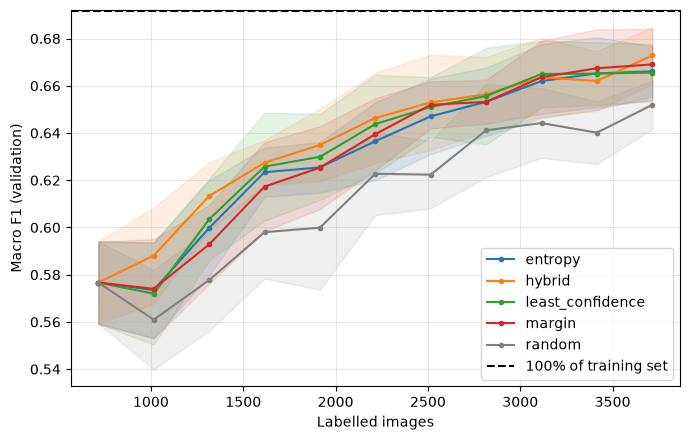

In [47]:
# Learning curves
# Mean and standard deviation of the validation macro F1 over the 10 seeds, for each strategy
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, g in curves.groupby("strategy"):
    m = g.groupby("n_labelled").val_f1.agg(["mean", "std"])  # mean and std at each number of labelled images
    color = "gray" if name == "random" else None             # random sampling in grey, to stand out
    line, = ax.plot(m.index, m["mean"], marker="o", ms=3, label=name, color=color)
    ax.fill_between(m.index, m["mean"] - m["std"], m["mean"] + m["std"], alpha=0.12, color=line.get_color()) # band with the same colour as the line
ax.axhline(f1_ref, ls="--", color="k", label="100% of training set")
ax.set_xlabel("Labelled images")
ax.set_ylabel("Macro F1 (validation)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

To understand why active learning helps, we count the classes of the images queried by each strategy, as a percentage of all queried images, and compare them with the class distribution of the training set.

In [48]:
# Requested classes
# Which classes each strategy requested (% of all requested images), compared with the training set
perc = pd.read_csv(TABLES / "al_requested_classes.csv", index_col=0)
perc

,akiec,bcc,bkl,df,mel,nv,vasc
strategy,,,,,,,
entropy,5.5,6.9,16.9,1.9,17.6,50.3,0.9
hybrid,5.5,7.1,17.1,1.8,17.3,50.4,0.9
least_confidence,5.3,6.6,16.7,1.8,17.7,51.0,0.9
margin,5.2,6.4,16.6,1.6,17.4,51.7,0.9
random,3.2,5.2,11.2,1.2,11.1,66.7,1.4
training set (all images),3.3,5.1,11.0,1.1,11.1,67.0,1.4


## 9. Statistical tests

To check whether the differences between query strategies are real and not due to chance, we compare them with paired statistical tests. For each seed, all strategies start from the same initial labelled set and the same model, so they can be compared seed by seed (paired design). Each run is summarised in two ways:

- **Mean over cycles:** the mean validation macro F1-score over the 10 cycles, which shows how fast the strategy learns.
- **Last cycle:** the validation macro F1-score with 50% of the images labelled, which shows the performance reached with the full labelling budget.

We use the two-sided Wilcoxon signed-rank test, which does not assume that the differences follow a normal distribution, and the Holm correction for multiple comparisons. A difference is considered significant when the corrected p-value (`p_holm`) is below 0.05. The functions below are the same as in `al_stats.py`.

In [49]:
def holm(p):
    # Holm correction for multiple comparisons.
    # Adjusts the p-values so that performing several tests does not increase the chance of a false positive, and returns them in the original order.
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.empty(len(p))
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def compare(table, reference, others, summary):
    # Compares each query strategy with a reference strategy, seed by seed.
    # For each comparison it reports the mean and standard deviation of the paired differences, the number of seeds in which the strategy was better, and the Wilcoxon p-value before and after the Holm correction.
    rows = []
    for s in others:
        diff = table[s] - table[reference]  # one paired difference per seed
        rows.append(dict(summary=summary, comparison=f"{s} vs {reference}", mean_diff=diff.mean(), std_diff=diff.std(), seeds_better=int((diff > 0).sum()), n_seeds=len(diff), p_wilcoxon=wilcoxon(table[s], table[reference]).pvalue))
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out.p_wilcoxon)
    return out

In [50]:
al = curves[curves.cycle > 0]  # cycle 0 is identical for all strategies, since no image has been queried yet
# Two tables with one row per seed and one column per query strategy
per_seed = {"mean over cycles": al.groupby(["strategy", "seed"]).val_f1.mean().unstack("strategy"), "last cycle": al[al.cycle == al.cycle.max()].set_index(["seed", "strategy"]).val_f1.unstack("strategy")}

strategies = [s for s in per_seed["last cycle"].columns if s != "random"]  # the four active learning strategies
best = per_seed["mean over cycles"][strategies].mean().idxmax()            # best strategy, chosen on validation

results = []
for summary, table in per_seed.items():
    results.append(compare(table, "random", strategies, summary))  # each active learning strategy against random sampling
results.append(compare(per_seed["mean over cycles"], best, [s for s in strategies if s != best], "mean over cycles"))  # best strategy against the other three

stats = pd.concat(results, ignore_index=True).round(4)
saved_stats = pd.read_csv(TABLES / "al_stats.csv")
print("Best strategy:", best, "| same as the saved table:", np.allclose(stats.select_dtypes("number"), saved_stats.select_dtypes("number")))
stats

Best strategy: hybrid | same as the saved table: True


,summary,comparison,mean_diff,std_diff,seeds_better,n_seeds,p_wilcoxon,p_holm
0,mean over cycles,entropy vs random,0.0193,0.0127,9,10,0.0039,0.0156
1,mean over cycles,hybrid vs random,0.0259,0.0178,9,10,0.0039,0.0156
2,mean over cycles,least_confidence vs random,0.0218,0.0133,9,10,0.0039,0.0156
3,mean over cycles,margin vs random,0.0195,0.0130,9,10,0.0059,0.0156
4,last cycle,entropy vs random,0.0142,0.0154,8,10,0.0273,0.0586
5,last cycle,hybrid vs random,0.0209,0.0129,10,10,0.0020,0.0078
6,last cycle,least_confidence vs random,0.0137,0.0165,8,10,0.0195,0.0586
7,last cycle,margin vs random,0.0171,0.0197,7,10,0.0645,0.0645
8,mean over cycles,entropy vs hybrid,-0.0066,0.0065,1,10,0.0059,0.0176
9,mean over cycles,least_confidence vs hybrid,-0.0041,0.0086,3,10,0.2754,0.2754


## 10. Annotation cost

The main goal of active learning is to reduce the annotation cost. We therefore measure how many labelled images each query strategy needs to reach 90% and 95% of the validation macro F1-score of the reference model trained with all the labels. For each seed, we record the first number of labelled images at which the target is reached and report the median over the 10 seeds, together with the number of seeds that reach the target within the labelling budget. The same quantity is also read on the mean learning curve. The code is the same as in `al_labels_to_target.py`.

In [51]:
# Labelled images needed to reach each target
max_n = curves.n_labelled.max()  # largest number of labelled images (labelling budget)
rows = []
for frac in [0.90, 0.95]:
    target = frac * f1_ref  # 90% and 95% of the reference macro F1
    for strategy, g in curves.groupby("strategy"):
        # For each seed, the first number of labelled images at which the target is reached (inf if it is never reached)
        first = pd.Series({seed: s.loc[s.val_f1 >= target, "n_labelled"].min() for seed, s in g.groupby("seed")}).fillna(np.inf)
        # The same quantity read on the mean learning curve over the 10 seeds
        mean_curve = g.groupby("n_labelled").val_f1.mean()
        reached = mean_curve[mean_curve >= target]
        med = first.median()  # median over the seeds
        rows.append(dict(target=f"{int(frac * 100)}% of full model (F1 >= {target:.3f})", strategy=strategy, seeds_reached=f"{int(np.isfinite(first).sum())}/{len(first)}", median_labels=int(med) if np.isfinite(med) else f">{max_n}", mean_curve_labels=int(reached.index.min()) if len(reached) else f">{max_n}"))

labels_to_target = pd.DataFrame(rows)
saved_ltt = pd.read_csv(TABLES / "al_labels_to_target.csv")
print("Same as the saved table:", labels_to_target.astype(str).equals(saved_ltt.astype(str)))
labels_to_target

Same as the saved table: True


,target,strategy,seeds_reached,median_labels,mean_curve_labels
0,90% of full model (F1 >= 0.623),entropy,10/10,1765,1615
1,90% of full model (F1 >= 0.623),hybrid,10/10,1615,1615
2,90% of full model (F1 >= 0.623),least_confidence,10/10,1765,1615
3,90% of full model (F1 >= 0.623),margin,10/10,1765,1915
4,90% of full model (F1 >= 0.623),random,10/10,2215,2215
5,95% of full model (F1 >= 0.657),entropy,9/10,2965,3115
6,95% of full model (F1 >= 0.657),hybrid,9/10,2515,3115
7,95% of full model (F1 >= 0.657),least_confidence,10/10,2665,3115
8,95% of full model (F1 >= 0.657),margin,10/10,3115,3115
9,95% of full model (F1 >= 0.657),random,5/10,>3715,>3715


## 11. Test set and noisy oracle

The test set was not used to select the query strategy. The hybrid strategy, selected on the validation set in section 9, and random sampling are run again with the 10 seeds, and the final model of each run (with 3715 labelled images, about 52% of the training set) is evaluated once on the test set.

In practice, the oracle is a dermatologist, and dermatologists also make mistakes. To study how annotation quality affects active learning, both strategies are also run with a noisy oracle, which gives a wrong class to 10% of the queried images. The initial labelled set is kept correct. In the tables and figures, the noisy oracle is named "noisy expert". Two references trained on 100% of the training images are added for comparison, our linear model and the passive baseline of notebook `03_passive_baseline.ipynb`.

These 40 runs were performed by `al_final.py`, using the function `run_experiment` of section 7 with `noise=NOISE` and `test=True`.

In [52]:
RETRAIN = False   # True runs the 40 final experiments again, False loads the saved results

if RETRAIN:
    # Best strategy and random sampling, each with a perfect and a noisy oracle, evaluated on the test set at the end
    rows = []
    for name, noise in [(best, 0.0), ("random", 0.0), (best, NOISE), ("random", NOISE)]:
        for seed in SEEDS:
            print("running", name, "| noise", noise, "| seed", seed, flush=True)
            rows += run_experiment(name, seed, d, noise=noise, test=True)
    res = pd.DataFrame(rows)
    res.to_csv(TABLES / "al_final_runs.csv", index=False)
else:
    res = pd.read_csv(TABLES / "al_final_runs.csv")

# Test results at the last cycle (mean and standard deviation over the 10 seeds)
final = res[res.cycle == res.cycle.max()].copy()
final["setting"] = np.where(final.noise > 0, final.strategy + " (10% noisy expert)", final.strategy)
print("Runs:", final.groupby("setting").size().to_dict())

# Test results, with the two references trained on 100% of the training images
test_results = pd.read_csv(TABLES / "al_test_results.csv", index_col=0)
test_results

Runs: {'hybrid': 10, 'hybrid (10% noisy expert)': 10, 'random': 10, 'random (10% noisy expert)': 10}


,test_f1,test_f1_std,test_bal_acc,test_bal_acc_std,test_recall_mel,test_recall_mel_std
setting,,,,,,
hybrid,0.6082,0.0109,0.6144,0.0132,0.5686,0.0374
hybrid (10% noisy expert),0.5091,0.0196,0.5846,0.0143,0.5371,0.0391
random,0.5742,0.0152,0.5930,0.0143,0.5811,0.0439
random (10% noisy expert),0.4290,0.0269,0.5606,0.0197,0.5396,0.0535
"100% of training set (ours, 1 run)",0.6391,NaN,0.6223,NaN,0.6101,NaN
"team baseline (100%, 1 run)",0.6227,NaN,0.6373,NaN,0.6918,NaN


As in section 9, the settings are compared seed by seed with the Wilcoxon signed-rank test, since for the same seed they start from the same labelled set and the same model.

In [53]:
# Paired comparison on the test set
# For the same seed, both settings start from the same labelled data and the same model
per_seed = final.pivot(index="seed", columns="setting", values="test_f1")
print("Paired comparison on the test set (macro F1, Wilcoxon signed-rank):")
for a, r in [(best, "random"), (best + " (10% noisy expert)", "random (10% noisy expert)"), (best + " (10% noisy expert)", best), ("random (10% noisy expert)", "random")]:
    diff = per_seed[a] - per_seed[r]  # one paired difference per seed
    print(f"{a} vs {r}: mean diff {diff.mean():+.4f} | better in {(diff > 0).sum()}/{len(diff)} seeds | p = {wilcoxon(per_seed[a], per_seed[r]).pvalue:.4f}")

Paired comparison on the test set (macro F1, Wilcoxon signed-rank):
hybrid vs random: mean diff +0.0340 | better in 10/10 seeds | p = 0.0020
hybrid (10% noisy expert) vs random (10% noisy expert): mean diff +0.0801 | better in 10/10 seeds | p = 0.0020
hybrid (10% noisy expert) vs hybrid: mean diff -0.0991 | better in 0/10 seeds | p = 0.0020
random (10% noisy expert) vs random: mean diff -0.1452 | better in 0/10 seeds | p = 0.0020


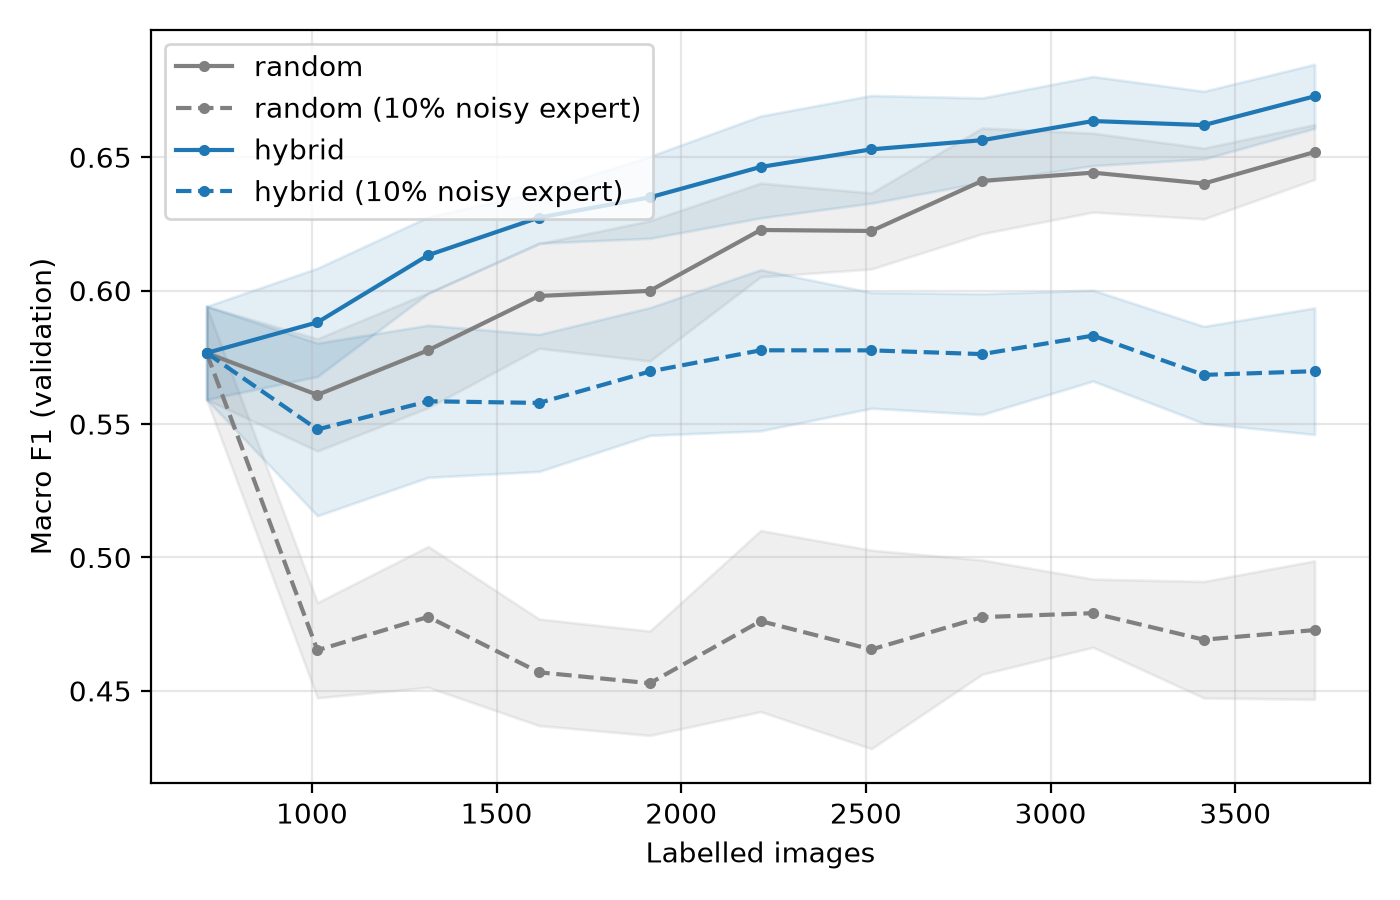

In [54]:
# Validation learning curves with a perfect and a noisy oracle (solid and dashed lines)
display(IPImage(filename=str(FIGURES / "al_noise.png"), width=600))

## 12. Saved results

The results of the active learning experiments are saved in the `results` folder:

- `tables/al_curves.csv`: validation macro F1-score after every cycle, for the five query strategies and the 10 seeds.
- `tables/al_requested_classes.csv`: percentage of each class among the images queried by each strategy.
- `tables/al_stats.csv`: paired comparisons between query strategies.
- `tables/al_labels_to_target.csv`: number of labelled images needed to reach 90% and 95% of the reference performance.
- `tables/al_final_runs.csv` and `tables/al_test_results.csv`: final runs and test results, with a correct and a noisy oracle.
- `figures/al_curves.png` and `figures/al_noise.png`: learning curves of sections 8 and 11.